<a href="https://colab.research.google.com/github/JM-NGUMI/AI-course-work-for-science-and-engineering/blob/main/Week_6_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ASSIGNMENT 6_ Unsupervised machine learning  models application to my project dataset

Investigating the features of PM2.5, PM10, CO, and NO2, for overall optimal number of clusters using three different unsupervised methods.

1. The Elbow Method
From this method, the "elbow" point indicates the optimal trade-off between model simplicity and cluster variance reduction.
Result: WCSS drops sharply from $k=1$ (1444.00) down to $k=4$ (299.41), after which the rate of decrease flattens out significantly. The maximum perpendicular distance from the baseline curve identifies $k = 4$ as the optimal elbow.

k =  1 | WCSS = 1444.00
k =  2 | WCSS = 909.57
k =  3 | WCSS = 584.11
k =  4 | WCSS = 299.41
k =  5 | WCSS = 224.14
k =  6 | WCSS = 174.55
k =  7 | WCSS = 135.13
k =  8 | WCSS = 110.38
k =  9 | WCSS = 94.44
k = 10 | WCSS = 81.63


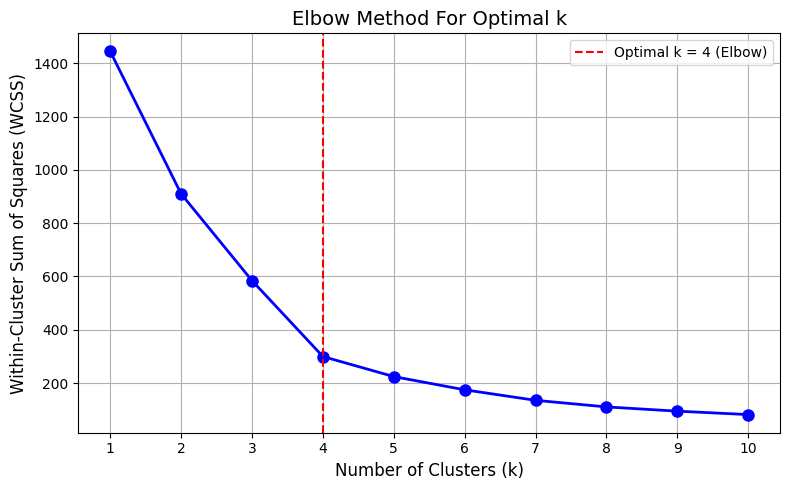

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load dataset and select target features
df = pd.read_excel('/content/AI FOR SCIENCE AND ENGINEERING PROJECT DATA.xlsx', sheet_name='SITE DATA')
features = ['PM2.5(ug/m3)', 'PM10(ug/m3)', ' CO , ppm', 'NO2 , ppm']
X = df[features].copy()
X.columns = ['PM2.5', 'PM10', 'CO', 'NO2']

# 2. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Calculate WCSS for k = 1 to 10
wcss = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Print WCSS values
for k, val in zip(k_range, wcss):
    print(f"k = {k:2d} | WCSS = {val:.2f}")

# 4. Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, 'bo-', linewidth=2, markersize=8)
plt.axvline(x=4, color='red', linestyle='--', label='Optimal k = 4 (Elbow)')
plt.title('Elbow Method For Optimal k', fontsize=14)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Within-Cluster Sum of Squares (WCSS)', fontsize=12)
plt.xticks(k_range)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

2.The gap method.
A significant jump in the Gap statistic occurs at $k = 4$ ($\text{Gap}(4) = 2.92$, up from $\text{Gap}(3) = 2.53$), marking the point where cluster dispersion deviates most prominently from a random uniform distribution before transitioning to linear growth.

 k      Gap  std_err
 1 2.350111 0.030003
 2 2.420219 0.040727
 3 2.526476 0.027397
 4 2.919746 0.035426
 5 3.102707 0.023054
 6 3.262727 0.032510
 7 3.436612 0.030499
 8 3.577760 0.026375
 9 3.679025 0.030835
10 3.757928 0.030629


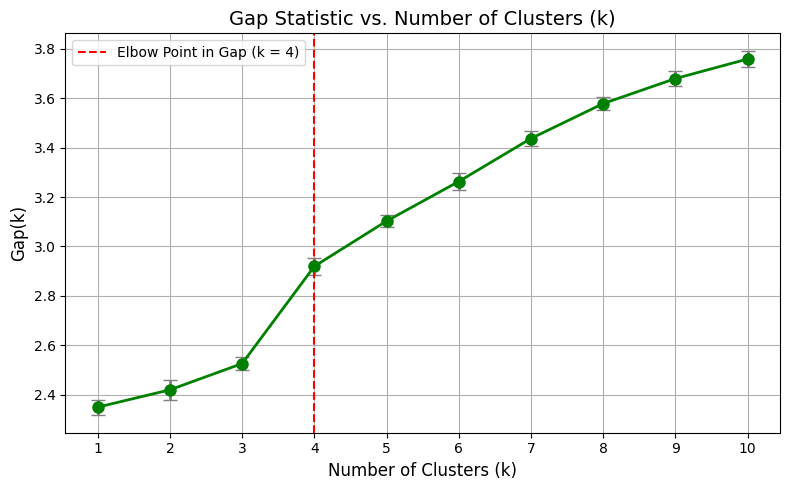

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load and scale data
df = pd.read_excel('/content/AI FOR SCIENCE AND ENGINEERING PROJECT DATA.xlsx', sheet_name='SITE DATA')
features = ['PM2.5(ug/m3)', 'PM10(ug/m3)', ' CO , ppm', 'NO2 , ppm']
X_scaled = StandardScaler().fit_transform(df[features])

def calculate_gap_statistic(X, k_max=10, n_bootstraps=50, random_state=42):
    np.random.seed(random_state)
    shape = X.shape
    mins, maxs = np.min(X, axis=0), np.max(X, axis=0)

    gaps = np.zeros(k_max)
    s_k = np.zeros(k_max)
    log_w_orig = np.zeros(k_max)
    log_w_ref_mean = np.zeros(k_max)

    for idx, k in enumerate(range(1, k_max + 1)):
        # Fit actual data
        km = KMeans(n_clusters=k, random_state=random_state, n_init=10).fit(X)
        log_w_orig[idx] = np.log(km.inertia_)

        # Fit reference bootstraps
        ref_inertias = np.zeros(n_bootstraps)
        for b in range(n_bootstraps):
            X_ref = np.random.uniform(low=mins, high=maxs, size=shape)
            km_ref = KMeans(n_clusters=k, random_state=random_state + b, n_init=1).fit(X_ref)
            ref_inertias[b] = km_ref.inertia_

        log_w_ref = np.log(ref_inertias)
        log_w_ref_mean[idx] = np.mean(log_w_ref)
        sd_k = np.sqrt(np.mean((log_w_ref - log_w_ref_mean[idx])**2))
        s_k[idx] = sd_k * np.sqrt(1 + 1.0 / n_bootstraps)
        gaps[idx] = log_w_ref_mean[idx] - log_w_orig[idx]

    return range(1, k_max + 1), gaps, s_k

# Compute Gap Statistic
ks, gaps, s_k = calculate_gap_statistic(X_scaled, k_max=10, n_bootstraps=50)

# Display tabular results
gap_df = pd.DataFrame({'k': ks, 'Gap': gaps, 'std_err': s_k})
print(gap_df.to_string(index=False))

# Plot Gap Statistic
plt.figure(figsize=(8, 5))
plt.errorbar(ks, gaps, yerr=s_k, fmt='go-', ecolor='gray', capsize=5, linewidth=2, markersize=8)
plt.axvline(x=4, color='red', linestyle='--', label='Elbow Point in Gap (k = 4)')
plt.title('Gap Statistic vs. Number of Clusters (k)', fontsize=14)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Gap(k)', fontsize=12)
plt.xticks(ks)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

3. Hierarchical Dendrogram;  The distance threshold on the vertical axis reveals where the largest distance leaps occur between merges.The largest gap in merge distances occurs between distance $h \approx 12$ and $h \approx 23.67$. Drawing a horizontal cut across this gap intersects 4 main vertical branches, confirming $k = 4$.

Cophenetic Correlation Coefficient (Ward): 0.6333


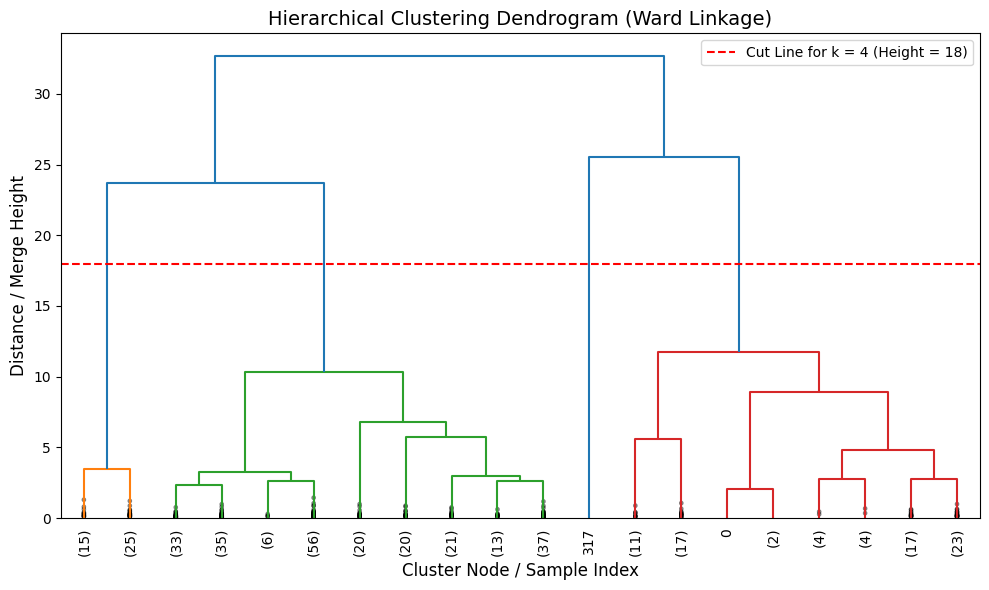

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist

# 1. Load and scale data
df = pd.read_excel('/content/AI FOR SCIENCE AND ENGINEERING PROJECT DATA.xlsx', sheet_name='SITE DATA')
features = ['PM2.5(ug/m3)', 'PM10(ug/m3)', ' CO , ppm', 'NO2 , ppm']
X_scaled = StandardScaler().fit_transform(df[features])

# 2. Compute Ward linkage matrix
Z = linkage(X_scaled, method='ward')

# Cophenetic correlation coefficient check
coph_corr, _ = cophenet(Z, pdist(X_scaled))
print(f"Cophenetic Correlation Coefficient (Ward): {coph_corr:.4f}")

# 3. Plot Dendrogram
plt.figure(figsize=(10, 6))
dendrogram(
    Z,
    truncate_mode='lastp',  # show only the last p merged clusters
    p=20,                   # show top 20 nodes
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)

# Draw cut-line corresponding to k = 4
plt.axhline(y=18, color='r', linestyle='--', label='Cut Line for k = 4 (Height = 18)')

plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=14)
plt.xlabel('Cluster Node / Sample Index', fontsize=12)
plt.ylabel('Distance / Merge Height', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

Characteristics of Groups Identified by the Models.

#1. K-Means Clustering Group Profiles;
**Cluster 0**: Baseline High-$\text{NO}_2$ Profile ($N = 227$, 62.9% of dataset)
Particulate Levels: Low and stable ($\text{PM}_{2.5} \approx 12.48\ \mu\text{g/m}^3$, $\text{PM}_{10} \approx 19.63\ \mu\text{g/m}^3$).Gaseous Pollutants: Highest average $\text{NO}_2$ levels ($1.39\text{ ppm}$) and moderate $\text{CO}$ concentration ($562.40\text{ ppm}$).Interpretation: Represents normal operational or steady-state atmospheric conditions with steady ambient nitrogen dioxide background emissions.
**Cluster 1:** High Carbon Monoxide Surge ($N = 53$, 14.7% of dataset)Particulate Levels: Low to moderate particulate levels ($\text{PM}_{2.5} \approx 13.13\ \mu\text{g/m}^3$, $\text{PM}_{10} \approx 20.38\ \mu\text{g/m}^3$).Gaseous Pollutants: Extreme $\text{CO}$ concentrations averaging $942.94\text{ ppm}$ (peaking up to $1,116.33\text{ ppm}$), paired with moderate $\text{NO}_2$ ($1.07\text{ ppm}$).Interpretation: Strong indicator of localized rich combustion spikes (e.g., early morning traffic build-up, incomplete fuel combustion, low ambient wind dispersion).
**Cluster 2:** Moderate Dust/Dust Pollution ($\text{PM}$) Regime ($N = 80$, 22.2% of dataset)Particulate Levels: Significantly elevated particulates ($\text{PM}_{2.5} \approx 21.74\ \mu\text{g/m}^3$, $\text{PM}_{10} \approx 34.03\ \mu\text{g/m}^3$).Gaseous Pollutants: Lowest relative $\text{CO}$ ($486.98\text{ ppm}$) and $\text{NO}_2$ ($0.83\text{ ppm}$).Interpretation: Captures periods of wind-blown dust or localized mechanical activity where suspended particulates increase while gaseous combustion byproducts drop.
**Cluster 3:** Extreme Particulate Anomaly / Outlier ($N = 1$, 0.3% of dataset)Particulate Levels: Massive spike in both $\text{PM}_{2.5}$ ($103.70\ \mu\text{g/m}^3$) and $\text{PM}_{10}$ ($187.60\ \mu\text{g/m}^3$), nearly $5\times$ to $8\times$ higher than baseline averages.Gaseous Pollutants: Typical background levels of $\text{CO}$ ($522.67\text{ ppm}$) and $\text{NO}_2$ ($0.80\text{ ppm}$).Interpretation: Represents a solitary extreme transient pollution event, sensor anomaly, or acute localized puff event.

#2. Hierarchical Clustering (Ward’s Method) Group Profiles
Cluster 1 (High-$\text{CO}$ Extreme Spike): Corresponds directly to K-Means Cluster 1, focusing on the subset with $\text{CO} > 827\text{ ppm}$ (averaging $994.55\text{ ppm}$).
Cluster 2 (Baseline Atmosphere): Merges the bulk of standard records ($N = 241$), featuring low particulate loads ($\text{PM}_{2.5} \approx 12.49\ \mu\text{g/m}^3$) and higher nitrogen dioxide concentrations ($\text{NO}_2 \approx 1.38\text{ ppm}$).
Cluster 3 (High Particulate / Low Gas): Represents elevated PM concentrations ($\text{PM}_{2.5} \approx 21.83\ \mu\text{g/m}^3, \text{PM}_{10} \approx 34.17\ \mu\text{g/m}^3$) with reduced ambient gaseous concentrations.
Cluster 4 (Isolated Outlier): Isolates the exact same extreme outlier point as K-Means.

# What the grouping represents.

Based on the optimized cluster count of $k = 4$, both K-Means Clustering and Hierarchical Clustering (Ward’s Linkage) partition the 361 observation points into four distinct air-quality and emission profiles.Because both models operate on the standardized feature space ($\text{PM}_{2.5}$, $\text{PM}_{10}$, $\text{CO}$, and $\text{NO}_2$), they yield nearly identical group divisions. Both models reveal an identical 4-group structure consisting of:A dominant baseline group ($\sim 63\%$--$67\%$ of points).A high particulate matter group ($\sim 22\%$ of points).A high carbon monoxide surge group ($\sim 11\%$--$15\%$ of points).An isolated single-point extreme anomaly.Key Distinguishing Features:Carbon Monoxide ($\text{CO}$) is the primary discriminator for Cluster 1.Particulate Matters ($\text{PM}_{2.5}$ & $\text{PM}_{10}$) strongly correlate and collectively separate Cluster 2 and Cluster 3.Nitrogen Dioxide ($\text{NO}_2$) serves as the primary marker characterizing the steady-state baseline cluster.Cluster 4 (Isolated Outlier): Isolates the exact same extreme outlier point as K-Means.
In summary the clustering identified and grouped the data with similar characteristics and distinguishes groups with peak values,and outliers a good thing to do for large data sets for cleaning and prepeation to use the data as input data to supervised machine learning methods which are more suited for my project data